## Day 1

Math required for machine learning

Statistics: Mean, median,mode variance, standard deviation, and probability.
Linear algebra: Vectors, vector operations, dot products, and matrices.
Calculus: Functions, limits, derivatives, and gradients.

## Day 2 

Implement the math concepts in code using numpy and pandas
Using Titanic dataset , for initial concepts.

Understanding Mean, median, mode variance, standard deviation

$$
Mean =\sum_{i=1}^{n} x_i

$$

Median is mid value when the weights are sorted.

Mode is most frequent occuring value , there can be multiple modes


$$Variance(\sigma^2) = \frac{\sum_{i=1}^{N} (x_i - \mu)^2}{N}$$
$$Standard\ deviation(\sigma) = \sqrt{\frac{\sum_{i=1}^{N} (x_i - \mu)^2}{N}}$$

In [34]:
import pandas as pd
import numpy as np

In [56]:
# reading data from csv file

df = pd.read_csv('../titanic-dataset.csv')

In [57]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [58]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [59]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [60]:
# taking numerical columns only


age = df['Age']
fair = df['Fare']

In [61]:
print("Mean of Age:", age.mean() , "Mean of Fare:", fair.mean())
print("Median of Age:", age.median(), "Median of Fare:", fair.median())
print("Mode of Age:", age.mode()[0], "Mode of Fare:", fair.mode()[0])
print("Standard Deviation of Age:", age.std(), "Standard Deviation of Fare:", fair.std())
print("Variance of Age:", age.var(), "Variance of Fare:", fair.var())

Mean of Age: 29.69911764705882 Mean of Fare: 32.204207968574636
Median of Age: 28.0 Median of Fare: 14.4542
Mode of Age: 24.0 Mode of Fare: 8.05
Standard Deviation of Age: 14.526497332334042 Standard Deviation of Fare: 49.6934285971809
Variance of Age: 211.01912474630802 Variance of Fare: 2469.436845743116


In [62]:
df["Age"][df["Age"]==24].count()

np.int64(30)

In [63]:


import random


random.choice([24, 25, 26, 27, 28])

26

In [71]:
df["Age"].fillna(df["Age"].mean(), inplace=True)

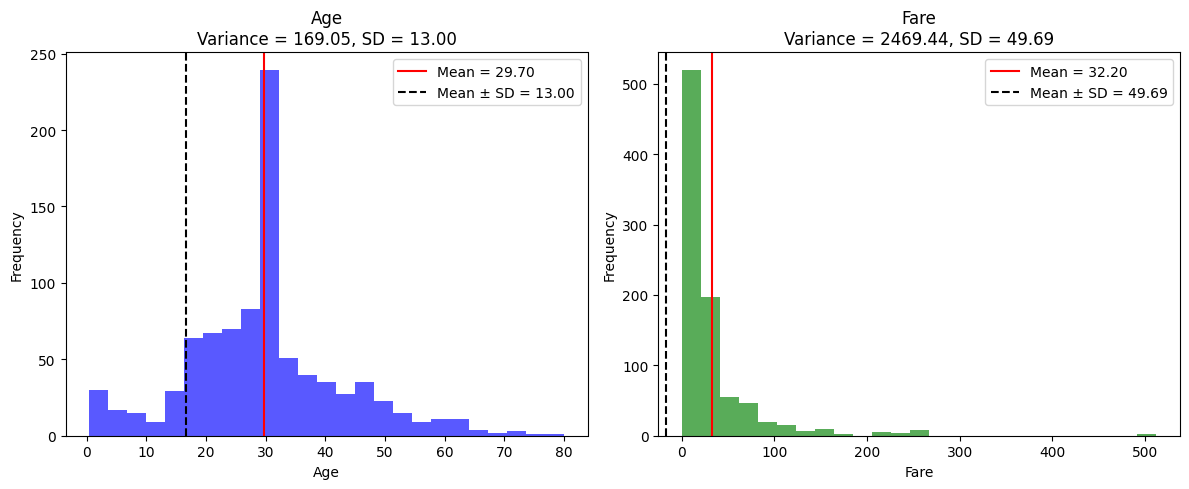

In [72]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, color in zip(
    axes, ["Age", "Fare"], ["blue", "green"]
):
    data = df[column].dropna()

    mean = data.mean()
    std = data.std(ddof=1)
    variance = data.var(ddof=1)

    ax.hist(data, bins=25, alpha=0.65, color=color)

    ax.axvline(mean, color="red", linestyle="-",
               label=f"Mean = {mean:.2f}")
    ax.axvline(mean - std, color="black", linestyle="--",
               label=f"Mean ± SD = {std:.2f}")
    ax.axvline(mean + std, color="black", linestyle="")

    ax.set_title(
        f"{column}\nVariance = {variance:.2f}, SD = {std:.2f}"
    )
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()